# 13 · Fair model comparison

All eight tuned models from notebooks 05–12, compared under the same conditions, following the **six rules of a fair comparison** from EC5203 Lecture 7.

| Rule (Lecture 7) | How this project follows it |
|---|---|
| 1 · Same data and folds | Same 46 dev homes, same 20 features, and the **same house-grouped folds** for every model |
| 2 · Same preprocessing rules | Every learned step (imputer, scaler, PCA) sits inside the pipeline, so it is fitted on the training folds only |
| 3 · Several metrics | macro-F1, balanced accuracy (= macro recall), macro ROC-AUC (one-vs-rest), macro average precision |
| 4 · Repeat CV | 5 folds × 5 repeats = **25 scores per model**, reported as **mean ± SD** |
| 5 · Equal tuning care | Every model got the same method in its own notebook: grouped grid search, then a 5-seed robustness check |
| 6 · Test set once | Models are ranked on CV only. Each test score was measured once in its own notebook and is just reported here |

**Tuning budget (rule 5):** every model searched its main settings plus its preprocessing.

| Model | Settings searched | Model | Settings searched |
|---|---|---|---|
| Random Forest | 36 | SVM (RBF) | 48 |
| Extra Trees | 36 | k-Nearest Neighbours | 80 (each fit is instant) |
| Gradient Boosting | 16 (each fit is slow) | Decision Tree | 64 |
| Logistic Regression | 40 | Gaussian Naive Bayes | 30 |

Sections: 1 setup · 2 repeated CV · 3 results · 4 did PCA help? · 5 what drives the prediction? · 6 where did it go wrong? · 7 report table and claims

## 1 · Setup: load the eight tuned pipelines

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import f1_score, average_precision_score, make_scorer

DATA = Path.home() / "Documents" / "10084619"
features = pd.read_csv(DATA / "features.csv").merge(pd.read_csv(DATA / "split.csv")[["id", "split"]], on="id")
dev = features[features["split"] == "dev"].reset_index(drop=True)
test = features[features["split"] == "test"].reset_index(drop=True)

NOTEBOOKS = {"rf": "05_RandomForest", "et": "06_ExtraTrees", "hgb": "07_GradientBoosting",
             "lr": "08_LogisticRegression", "svm": "09_SVM", "knn": "10_kNN",
             "dt": "11_DecisionTree", "nb": "12_NaiveBayes"}
bundles = {}
for short, nb in NOTEBOOKS.items():
    path = DATA / f"model_{short}.joblib"
    assert path.exists(), f"{path.name} is missing: run {nb}.ipynb first"
    b = joblib.load(path)
    bundles[b["model"]] = b

FINAL = bundles["Random Forest"]["features"]
assert all(b["features"] == FINAL for b in bundles.values()), "every model must use the same 20 features"
models = {name: clone(b["pipeline"]) for name, b in bundles.items()}   # tuned settings, no fitted weights

X_dev, y_dev, g_dev = dev[FINAL], dev["type"], dev["location"]
SEEDS = range(5)                     # 5 repeats x 5 house-grouped folds = 25 scores per model
METRICS = {"macro-F1": "f1_macro", "balanced accuracy": "balanced_accuracy",
           "ROC-AUC (macro OvR)": "roc_auc_ovr",
           # probabilities for every model: raw linear scores are not comparable across recordings
           "avg precision (macro)": make_scorer(average_precision_score, response_method="predict_proba", average="macro")}

def repeated_cv(model):
    """The same 25 house-grouped folds for every model; one row per fold."""
    rows = []
    for s in SEEDS:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
        r = cross_validate(model, X_dev, y_dev, groups=g_dev, cv=cv, scoring=METRICS, n_jobs=-1)
        rows += [{"seed": s, "fold": k, **{m: r[f"test_{m}"][k] for m in METRICS}} for k in range(5)]
    return pd.DataFrame(rows)

print(f"{len(models)} tuned models | {len(FINAL)} features | dev: {len(dev)} recordings, {g_dev.nunique()} homes")
display(pd.Series({n: "; ".join(f"{k}={v}" for k, v in b["params"].items()) for n, b in bundles.items()},
                  name="chosen settings (from notebooks 05–12)").to_frame())

8 tuned models | 20 features | dev: 1447 recordings, 46 homes


,chosen settings (from notebooks 05–12)
Random Forest,simpleimputer=passthrough; max_features=sqrt; ...
Extra Trees,simpleimputer=SimpleImputer(strategy='median')...
Gradient Boosting (HGB),simpleimputer=passthrough; learning_rate=0.05;...
Logistic Regression,simpleimputer=SimpleImputer(add_indicator=True...
SVM (RBF kernel),simpleimputer=SimpleImputer(add_indicator=True...
k-Nearest Neighbours,simpleimputer=SimpleImputer(strategy='median')...
Decision Tree,simpleimputer=passthrough; max_depth=10; min_s...
Gaussian Naive Bayes,simpleimputer=SimpleImputer(add_indicator=True...


## 2 · Repeated cross-validation (rules 1, 3, 4)

Every model is scored on exactly the same 25 folds. Each fold holds out whole homes, so every score is a score on unseen houses.

In [2]:
per_model = {}
for name, model in models.items():
    t0 = time.perf_counter()
    per_model[name] = repeated_cv(model)
    print(f"{name:<24} {time.perf_counter() - t0:6.1f} s")
scores = pd.concat(per_model, names=["model"]).reset_index(level=0).reset_index(drop=True)

Random Forest              22.7 s


Extra Trees                10.8 s


Gradient Boosting (HGB)    43.0 s


Logistic Regression         1.6 s


SVM (RBF kernel)            3.3 s


k-Nearest Neighbours        0.7 s


Decision Tree               0.7 s


Gaussian Naive Bayes        0.7 s


## 3 · Results: mean ± SD over 25 folds

The table ranks the models by CV macro-F1. The test column comes from each model's own notebook (10 locked homes, measured once).
"Same folds: do the bars separate?" When the ± is as big as the gap between two bars, the bars alone cannot rank the models. Because every model saw the same folds, the **paired** difference (fold by fold) is the fairer test.

,macro-F1,balanced accuracy,ROC-AUC (macro OvR),avg precision (macro),test macro-F1
model (ranked by CV macro-F1),,,,,
Random Forest,0.886 ± 0.021,0.879 ± 0.024,0.986 ± 0.004,0.928 ± 0.021,0.909
Gradient Boosting (HGB),0.874 ± 0.038,0.874 ± 0.037,0.979 ± 0.013,0.919 ± 0.038,0.887
Extra Trees,0.871 ± 0.053,0.867 ± 0.051,0.985 ± 0.004,0.915 ± 0.044,0.912
k-Nearest Neighbours,0.841 ± 0.062,0.838 ± 0.057,0.947 ± 0.016,0.844 ± 0.054,0.813
Logistic Regression,0.822 ± 0.037,0.830 ± 0.043,0.976 ± 0.007,0.860 ± 0.030,0.842
SVM (RBF kernel),0.818 ± 0.061,0.825 ± 0.059,0.963 ± 0.021,0.836 ± 0.051,0.849
Gaussian Naive Bayes,0.762 ± 0.031,0.772 ± 0.027,0.966 ± 0.011,0.814 ± 0.032,0.745
Decision Tree,0.720 ± 0.054,0.741 ± 0.048,0.866 ± 0.025,0.633 ± 0.059,0.848


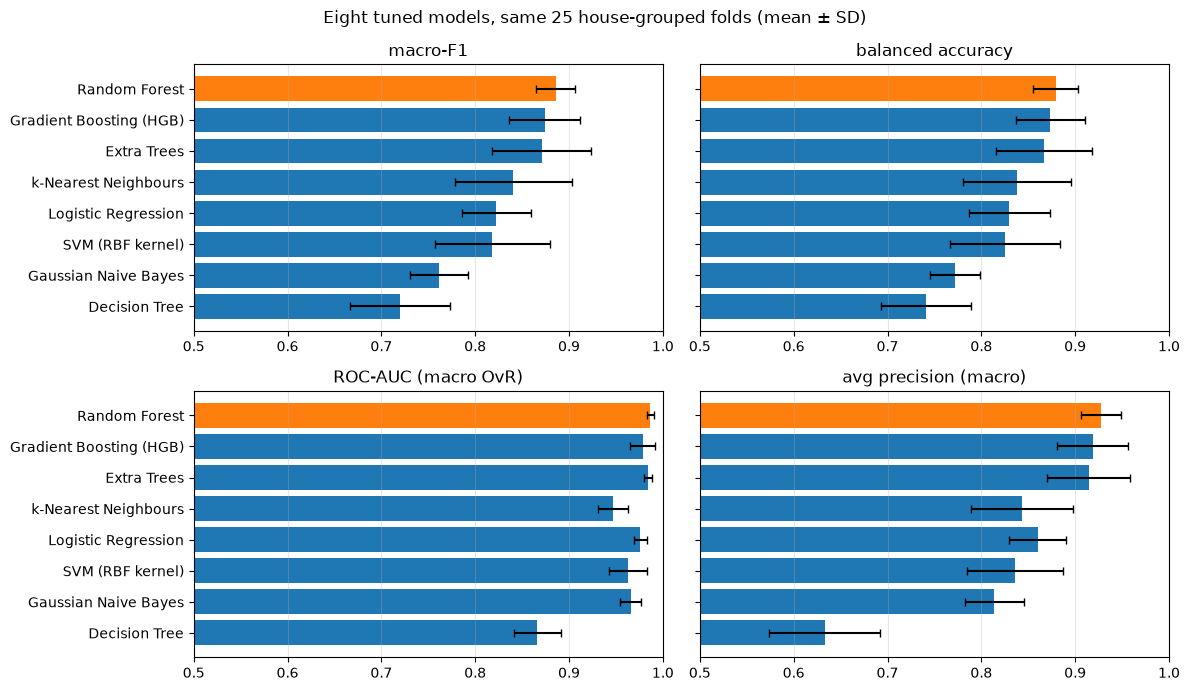

,macro-F1 minus Random Forest,SD,folds where Random Forest is better (of 25)
model,,,
Gradient Boosting (HGB),-0.012,0.039,16
Extra Trees,-0.015,0.040,16
k-Nearest Neighbours,-0.045,0.047,22
Logistic Regression,-0.063,0.025,25
SVM (RBF kernel),-0.068,0.056,21
Gaussian Naive Bayes,-0.124,0.037,25
Decision Tree,-0.166,0.052,25


Evidence, one sentence per model:
- Gradient Boosting (HGB): -0.012 macro-F1 against Random Forest on the same 25 folds; Random Forest was better in 16 of 25 folds.
- Extra Trees: -0.015 macro-F1 against Random Forest on the same 25 folds; Random Forest was better in 16 of 25 folds.
- k-Nearest Neighbours: -0.045 macro-F1 against Random Forest on the same 25 folds; Random Forest was better in 22 of 25 folds.
- Logistic Regression: -0.063 macro-F1 against Random Forest on the same 25 folds; Random Forest was better in 25 of 25 folds.
- SVM (RBF kernel): -0.068 macro-F1 against Random Forest on the same 25 folds; Random Forest was better in 21 of 25 folds.
- Gaussian Naive Bayes: -0.124 macro-F1 against Random Forest on the same 25 folds; Random Forest was better in 25 of 25 folds.
- Decision Tree: -0.166 macro-F1 against Random Forest on the same 25 folds; Random Forest was better in 25 of 25 folds.


In [3]:
summary = scores.groupby("model")[list(METRICS)].agg(["mean", "std"])
order = summary[("macro-F1", "mean")].sort_values(ascending=False).index.tolist()
best = order[0]

table = pd.DataFrame({m: [f"{summary.loc[n, (m, 'mean')]:.3f} ± {summary.loc[n, (m, 'std')]:.3f}" for n in order]
                      for m in METRICS}, index=pd.Index(order, name="model (ranked by CV macro-F1)"))
table["test macro-F1"] = [bundles[n]["scores"]["test_macro_f1"] for n in order]
display(table)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, m in zip(axes.ravel(), METRICS):
    ax.barh(order, summary.loc[order, (m, "mean")], xerr=summary.loc[order, (m, "std")],
            color=["tab:orange" if n == best else "tab:blue" for n in order], capsize=3)
    ax.set_title(m); ax.set_xlim(0.5, 1.0); ax.grid(axis="x", alpha=0.3)
axes[0, 0].invert_yaxis()
fig.suptitle("Eight tuned models, same 25 house-grouped folds (mean ± SD)")
plt.tight_layout(); plt.show()

# Paired comparison against the best model, fold by fold
f1 = scores.pivot_table(index=["seed", "fold"], columns="model", values="macro-F1")
diff = f1.sub(f1[best], axis=0)
paired = pd.DataFrame({f"macro-F1 minus {best}": diff.mean().round(3), "SD": diff.std(ddof=1).round(3),
                       f"folds where {best} is better (of 25)": (diff < 0).sum()}).loc[order[1:]]
display(paired)

print("Evidence, one sentence per model:")
for n in order[1:]:
    print(f"- {n}: {diff[n].mean():+.3f} macro-F1 against {best} on the same 25 folds; "
          f"{best} was better in {(diff[n] < 0).sum()} of 25 folds.")

## 4 · Did PCA help? Say it honestly

PCA finds new axes (principal components) that keep as much variance as possible, so 20 correlated features can be squeezed into fewer numbers. Following Lecture 7: **scale first**, keep **95% of the variance**, and put PCA **inside the pipeline** so it is learned on the training folds only.
PCA is tested on the four models that work with distances, margins or Gaussian shapes (Logistic Regression, SVM, kNN, Naive Bayes), and on Random Forest as a check. The PCA versions are scored on the same 25 folds, so the change is a paired, fold-by-fold comparison. We call it a real change only if it is bigger than one standard error (computed over the 5 repeats).

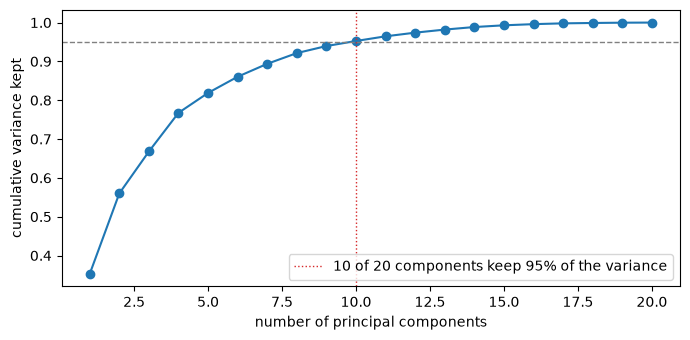

,without PCA,with PCA (95%),change,SE of change,folds where PCA helped (of 25)
model,,,,,
Logistic Regression,0.822,0.746,-0.077,0.004,5
SVM (RBF kernel),0.818,0.799,-0.019,0.001,7
k-Nearest Neighbours,0.841,0.763,-0.078,0.004,0
Gaussian Naive Bayes,0.762,0.653,-0.108,0.005,0
Random Forest,0.886,0.761,-0.125,0.004,0


- Logistic Regression: PCA hurt (-0.077 macro-F1, better in 5 of 25 folds).
- SVM (RBF kernel): PCA hurt (-0.019 macro-F1, better in 7 of 25 folds).
- k-Nearest Neighbours: PCA hurt (-0.078 macro-F1, better in 0 of 25 folds).
- Gaussian Naive Bayes: PCA hurt (-0.108 macro-F1, better in 0 of 25 folds).
- Random Forest: PCA hurt (-0.125 macro-F1, better in 0 of 25 folds).


In [4]:
# 4a. How many components keep 95% of the variance? (fitted on dev only, for this plot)
Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X_dev))
cum = np.cumsum(PCA().fit(Z).explained_variance_ratio_)
k95 = int(np.searchsorted(cum, 0.95) + 1)
plt.figure(figsize=(7, 3.5))
plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.95, ls="--", c="grey", lw=1)
plt.axvline(k95, ls=":", c="tab:red", lw=1, label=f"{k95} of {len(cum)} components keep 95% of the variance")
plt.xlabel("number of principal components"); plt.ylabel("cumulative variance kept")
plt.legend(); plt.tight_layout(); plt.show()

# 4b. Same 25 folds with "impute -> scale -> PCA(95%)" in front of each tuned model
def with_pca(pipe):
    # PCA cannot take NaN, so a median imputer goes first (no effect when the model already imputes)
    return Pipeline(pipe.steps[:-1] + [("pca_impute", SimpleImputer(strategy="median")),
                                       ("pca_scale", StandardScaler()),
                                       ("pca", PCA(n_components=0.95)), pipe.steps[-1]])

def change_se(d):
    # folds inside one repeat share data, so the 5 repeat means are the independent units
    return d.reshape(len(SEEDS), -1).mean(axis=1).std(ddof=1) / np.sqrt(len(SEEDS))

rows = []
for name in ["Logistic Regression", "SVM (RBF kernel)", "k-Nearest Neighbours", "Gaussian Naive Bayes", "Random Forest"]:
    with_ = repeated_cv(with_pca(models[name]))["macro-F1"].to_numpy()
    without = per_model[name]["macro-F1"].to_numpy()
    d = with_ - without
    rows.append({"model": name, "without PCA": without.mean(), "with PCA (95%)": with_.mean(),
                 "change": d.mean(), "SE of change": change_se(d), "folds where PCA helped (of 25)": int((d > 0).sum())})
pca_table = pd.DataFrame(rows).set_index("model")
display(pca_table.round(3))

for n, r in pca_table.iterrows():
    verdict = ("helped" if r["change"] > r["SE of change"] else
               "hurt" if r["change"] < -r["SE of change"] else "made no clear difference")
    print(f"- {n}: PCA {verdict} ({r['change']:+.3f} macro-F1, better in {int(r['folds where PCA helped (of 25)'])} of 25 folds).")

## 5 · What drives the prediction? (best model)

Lecture 7: shuffling **one column** can hide its importance, because correlated features cover for it. Shuffling a **whole group** at once (the same row shuffle for every column in the group) shows which kind of measurement the model really relies on.
Our 20 features come from four physical measurement groups, so we shuffle those. The score is the drop in macro-F1 on held-out homes (5 grouped folds × 5 shuffles).

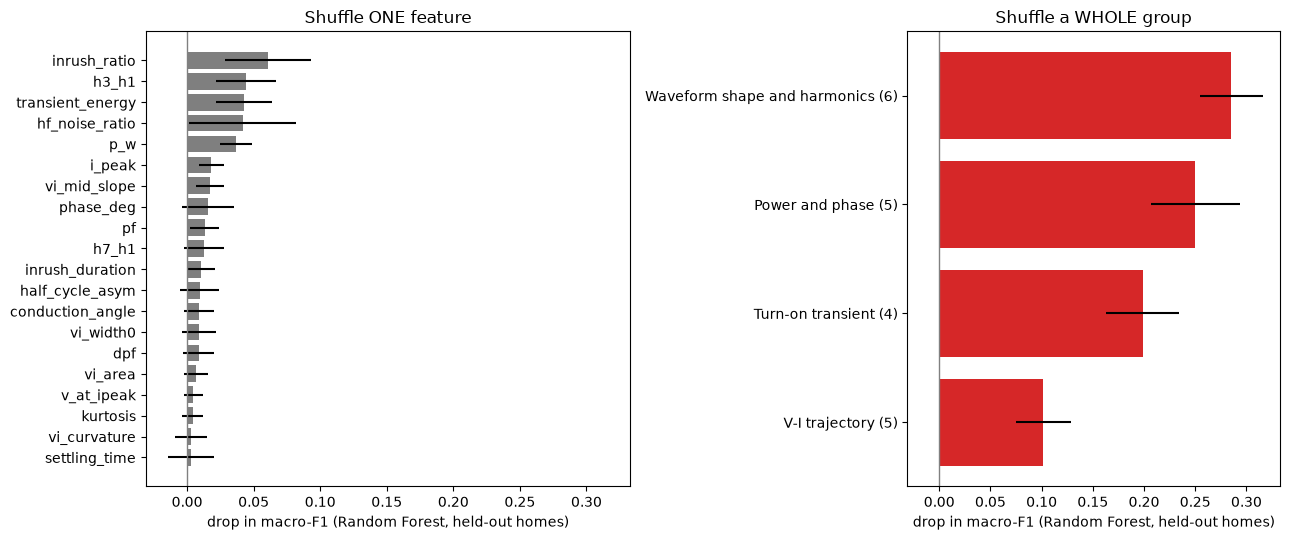

,drop,SD
Waveform shape and harmonics (6),0.285,0.031
Power and phase (5),0.250,0.043
Turn-on transient (4),0.199,0.036
V-I trajectory (5),0.102,0.027


Take-away: Random Forest relies most on the waveform shape and harmonics features (macro-F1 drops by 0.285 when that group is shuffled; the biggest single feature drops it by 0.061).
This shows what the model uses, not what physically causes an appliance type.


In [5]:
GROUPS = {"Power and phase (5)": ["p_w", "i_peak", "pf", "dpf", "phase_deg"],
          "Waveform shape and harmonics (6)": ["h3_h1", "h7_h1", "hf_noise_ratio", "kurtosis", "conduction_angle", "half_cycle_asym"],
          "V-I trajectory (5)": ["vi_area", "vi_mid_slope", "vi_width0", "vi_curvature", "v_at_ipeak"],
          "Turn-on transient (4)": ["inrush_ratio", "transient_energy", "inrush_duration", "settling_time"]}
assert sorted(sum(GROUPS.values(), [])) == sorted(FINAL), "every feature must be in exactly one group"

shuffles = {**GROUPS, **{f: [f] for f in FINAL}}
drops = {k: [] for k in shuffles}
rng = np.random.default_rng(0)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
for tr, va in cv.split(X_dev, y_dev, g_dev):
    m = clone(models[best]).fit(X_dev.iloc[tr], y_dev.iloc[tr])
    Xv, yv = X_dev.iloc[va], y_dev.iloc[va]
    base_f1 = f1_score(yv, m.predict(Xv), average="macro")
    for k, cols in shuffles.items():
        for _ in range(5):
            Xp = Xv.copy()
            Xp[cols] = Xv[cols].to_numpy()[rng.permutation(len(Xv))]   # one row shuffle for the whole group
            drops[k].append(base_f1 - f1_score(yv, m.predict(Xp), average="macro"))

imp = pd.DataFrame({k: {"drop": np.mean(v), "SD": np.std(v, ddof=1)} for k, v in drops.items()}).T
one, grp = imp.loc[FINAL].sort_values("drop"), imp.loc[list(GROUPS)].sort_values("drop")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, gridspec_kw={"width_ratios": [1.3, 1]})
a1.barh(one.index, one["drop"], xerr=one["SD"], color="tab:gray"); a1.set_title("Shuffle ONE feature")
a2.barh(grp.index, grp["drop"], xerr=grp["SD"], color="tab:red"); a2.set_title("Shuffle a WHOLE group")
for a in (a1, a2):
    a.axvline(0, c="grey", lw=1); a.set_xlabel(f"drop in macro-F1 ({best}, held-out homes)")
plt.tight_layout(); plt.show()
display(grp.iloc[::-1].round(3))

top_group = grp.index[-1]
print(f"Take-away: {best} relies most on the {top_group.split(' (')[0].lower()} features "
      f"(macro-F1 drops by {grp['drop'].iloc[-1]:.3f} when that group is shuffled; the biggest single feature "
      f"drops it by {one['drop'].iloc[-1]:.3f}).")
print("This shows what the model uses, not what physically causes an appliance type.")

## 6 · Where did it go wrong? Read the mistakes

The chosen model (best by CV), trained on the 46 dev homes and applied once to the 10 locked test homes, as in its own notebook. A confidence below 0.5 means a close call.

In [6]:
chosen = clone(models[best]).fit(X_dev, y_dev)
proba = chosen.predict_proba(test[FINAL])
pred, conf = chosen.classes_[proba.argmax(axis=1)], proba.max(axis=1)
miss = pred != test["type"].to_numpy()
wrong = test.loc[miss, ["id", "location", "type"] + FINAL].assign(predicted=pred[miss], confidence=conf[miss].round(2))

print(f"{best} on the 10 test homes: {miss.sum()} mistakes out of {len(test)} recordings "
      f"({(conf[miss] < 0.5).sum()} were close calls with confidence below 0.5).")
by_home = wrong["location"].value_counts()
print(f"{by_home.iloc[0]} of the {miss.sum()} mistakes come from one home ({by_home.index[0]}).")

pairs = (wrong.groupby(["type", "predicted"])
         .agg(mistakes=("id", "size"), mean_confidence=("confidence", "mean"),
              homes=("location", lambda s: ", ".join(sorted(set(s)))))
         .sort_values("mistakes", ascending=False))
display(pairs.round(2).head(8))

# The biggest confusion: do the mistaken recordings look like the class they were given?
true_c, pred_c = pairs.index[0]
key = one["drop"].nlargest(3).index.tolist()                  # the three features the model relies on most
mistaken = wrong[(wrong["type"] == true_c) & (wrong["predicted"] == pred_c)]
display(pd.DataFrame({f"typical {true_c} (dev median)": dev.loc[dev["type"] == true_c, key].median(),
                      f"the {len(mistaken)} mistaken recordings (median)": mistaken[key].median(),
                      f"typical {pred_c} (dev median)": dev.loc[dev["type"] == pred_c, key].median()}).round(3))

Random Forest on the 10 test homes: 33 mistakes out of 363 recordings (27 were close calls with confidence below 0.5).
18 of the 33 mistakes come from one home (house8).


,,mistakes,mean_confidence,homes
type,predicted,,,
Air Conditioner,Fan,9,0.52,"house22, house8"
Incandescent Light Bulb,Air Conditioner,5,0.25,house8
Air Conditioner,Fridge,4,0.80,"house22, house8"
Fridge,Incandescent Light Bulb,3,0.57,"house10, house22, house34"
Fan,Air Conditioner,3,0.41,house14
Fridge,Fan,2,0.32,"house10, house8"
Air Conditioner,Washing Machine,1,0.23,house8
Fridge,Washing Machine,1,0.34,house22


,typical Air Conditioner (dev median),the 9 mistaken recordings (median),typical Fan (dev median)
inrush_ratio,1.659,1.282,1.211
h3_h1,0.084,0.040,0.049
transient_energy,0.493,0.179,0.001


## 7 · Report table and what we can claim

The table follows the Lecture 7 report template: model, CV score (mean ± SD), test score, one strength, one limitation. Each strength and limitation is backed by a result from notebooks 05–13.

In [7]:
NOTES = {  # one strength and one limitation per model, each backed by our results
    "Random Forest": ("Learns thresholds and interactions; most stable across house splits", "Large file; one decision is hard to explain"),
    "Extra Trees": ("Fast; random splits act as regularisation", "Less stable across house splits (04, 06)"),
    "Gradient Boosting (HGB)": ("Learns from missing values; small model file", "Many settings; weakest on motor loads (fans)"),
    "Logistic Regression": ("Readable weights; tiny and fast", "Only straight boundaries; confuses heater and hairdryer"),
    "SVM (RBF kernel)": ("Curved, maximum-margin boundaries", "Needs scaling and joint C/gamma tuning; hard to explain"),
    "k-Nearest Neighbours": ("No training; explains by similar recordings", "Distances depend on scaling; stores all data"),
    "Decision Tree": ("Readable if-then rules (see 11)", "High variance: overfits and changes with the training homes"),
    "Gaussian Naive Bayes": ("Tiny, fast, few settings", "Assumes independent bell-shaped features; ours are linked"),
}
report = pd.DataFrame({
    "CV macro-F1 (mean ± SD)": table["macro-F1"],
    "CV balanced accuracy": table["balanced accuracy"],
    "test macro-F1": table["test macro-F1"],
    "strength": [NOTES[n][0] for n in order],
    "limitation": [NOTES[n][1] for n in order],
}, index=table.index)
display(report)

b = bundles[best]["scores"]
lo, hi = b["test_macro_f1_95ci"]
second = order[1]
print("WHAT WE CAN SAY (data, metric, split and uncertainty first):")
print(f"- On PLAID (46 dev homes, 5x5 house-grouped CV), {best} had the highest macro-F1: "
      f"{summary.loc[best, ('macro-F1', 'mean')]:.3f} ± {summary.loc[best, ('macro-F1', 'std')]:.3f}.")
print(f"- Against the runner-up ({second}) the gap is {-diff[second].mean():.3f}, and {best} was better in "
      f"{(diff[second] < 0).sum()} of the same 25 folds.")
print(f"- On 10 unseen test homes, {best} scored macro-F1 {b['test_macro_f1']:.3f} "
      f"(95% interval over homes {lo:.3f}–{hi:.3f}).")
helped = pca_table.index[pca_table["change"] > pca_table["SE of change"]].tolist()
hurt = pca_table.index[pca_table["change"] < -pca_table["SE of change"]].tolist()
print(f"- PCA (95% variance, {k95} components) helped {len(helped)} and hurt {len(hurt)} of the {len(pca_table)} models tested "
      f"(hurt: {', '.join(hurt) or 'none'}; section 4).")
print(f"- {best} relies most on the {top_group.split(' (')[0].lower()} group of features.")
print("WHAT WE CANNOT CONCLUDE:")
print(f"- That {best} is the best algorithm for appliance identification in general (one dataset, one feature set).")
print("- That a feature group causes an appliance type (importance is not causation).")
print(f"- That it will reach {b['test_macro_f1']:.2f} in any home (10 test homes; the interval is wide).")

,CV macro-F1 (mean ± SD),CV balanced accuracy,test macro-F1,strength,limitation
model (ranked by CV macro-F1),,,,,
Random Forest,0.886 ± 0.021,0.879 ± 0.024,0.909,Learns thresholds and interactions; most stabl...,Large file; one decision is hard to explain
Gradient Boosting (HGB),0.874 ± 0.038,0.874 ± 0.037,0.887,Learns from missing values; small model file,Many settings; weakest on motor loads (fans)
Extra Trees,0.871 ± 0.053,0.867 ± 0.051,0.912,Fast; random splits act as regularisation,"Less stable across house splits (04, 06)"
k-Nearest Neighbours,0.841 ± 0.062,0.838 ± 0.057,0.813,No training; explains by similar recordings,Distances depend on scaling; stores all data
Logistic Regression,0.822 ± 0.037,0.830 ± 0.043,0.842,Readable weights; tiny and fast,Only straight boundaries; confuses heater and ...
SVM (RBF kernel),0.818 ± 0.061,0.825 ± 0.059,0.849,"Curved, maximum-margin boundaries",Needs scaling and joint C/gamma tuning; hard t...
Gaussian Naive Bayes,0.762 ± 0.031,0.772 ± 0.027,0.745,"Tiny, fast, few settings",Assumes independent bell-shaped features; ours...
Decision Tree,0.720 ± 0.054,0.741 ± 0.048,0.848,Readable if-then rules (see 11),High variance: overfits and changes with the t...


WHAT WE CAN SAY (data, metric, split and uncertainty first):
- On PLAID (46 dev homes, 5x5 house-grouped CV), Random Forest had the highest macro-F1: 0.886 ± 0.021.
- Against the runner-up (Gradient Boosting (HGB)) the gap is 0.012, and Random Forest was better in 16 of the same 25 folds.
- On 10 unseen test homes, Random Forest scored macro-F1 0.909 (95% interval over homes 0.756–0.941).
- PCA (95% variance, 10 components) helped 0 and hurt 5 of the 5 models tested (hurt: Logistic Regression, SVM (RBF kernel), k-Nearest Neighbours, Gaussian Naive Bayes, Random Forest; section 4).
- Random Forest relies most on the waveform shape and harmonics group of features.
WHAT WE CANNOT CONCLUDE:
- That Random Forest is the best algorithm for appliance identification in general (one dataset, one feature set).
- That a feature group causes an appliance type (importance is not causation).
- That it will reach 0.91 in any home (10 test homes; the interval is wide).
